# Data Loading

In [2]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.060014
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,5.107523
948,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.660810
3160,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.529859
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.130936


# Prediction Analysis

## Metrics

In [3]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.363016,0.370493,0.269559,0.519191
Split 1,0.382005,0.426635,0.341337,0.584241
Split 2,0.389242,0.386876,0.269922,0.519540
Split 3,0.260399,0.449202,0.418460,0.646885
Split 4,0.414194,0.362477,0.280856,0.529958
Split 5,0.416701,0.392612,0.308557,0.555479
Split 6,0.440606,0.347485,0.236187,0.485991
Split 7,0.316537,0.392339,0.295290,0.543406
Split 8,0.366147,0.377821,0.328665,0.573293
Split 9,0.425891,0.359262,0.272180,0.521709


# Graph

Text(0, 0.5, 'predicted pIC50')

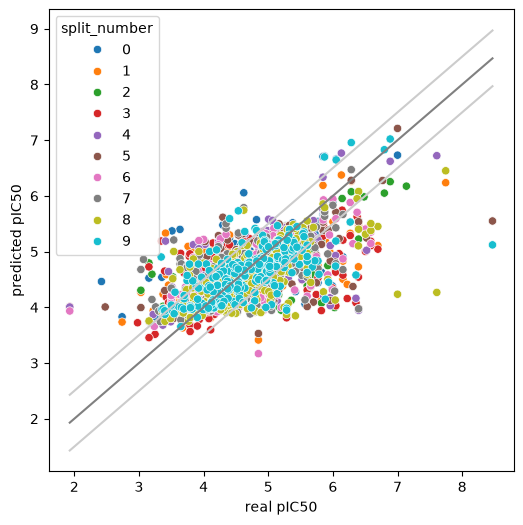

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

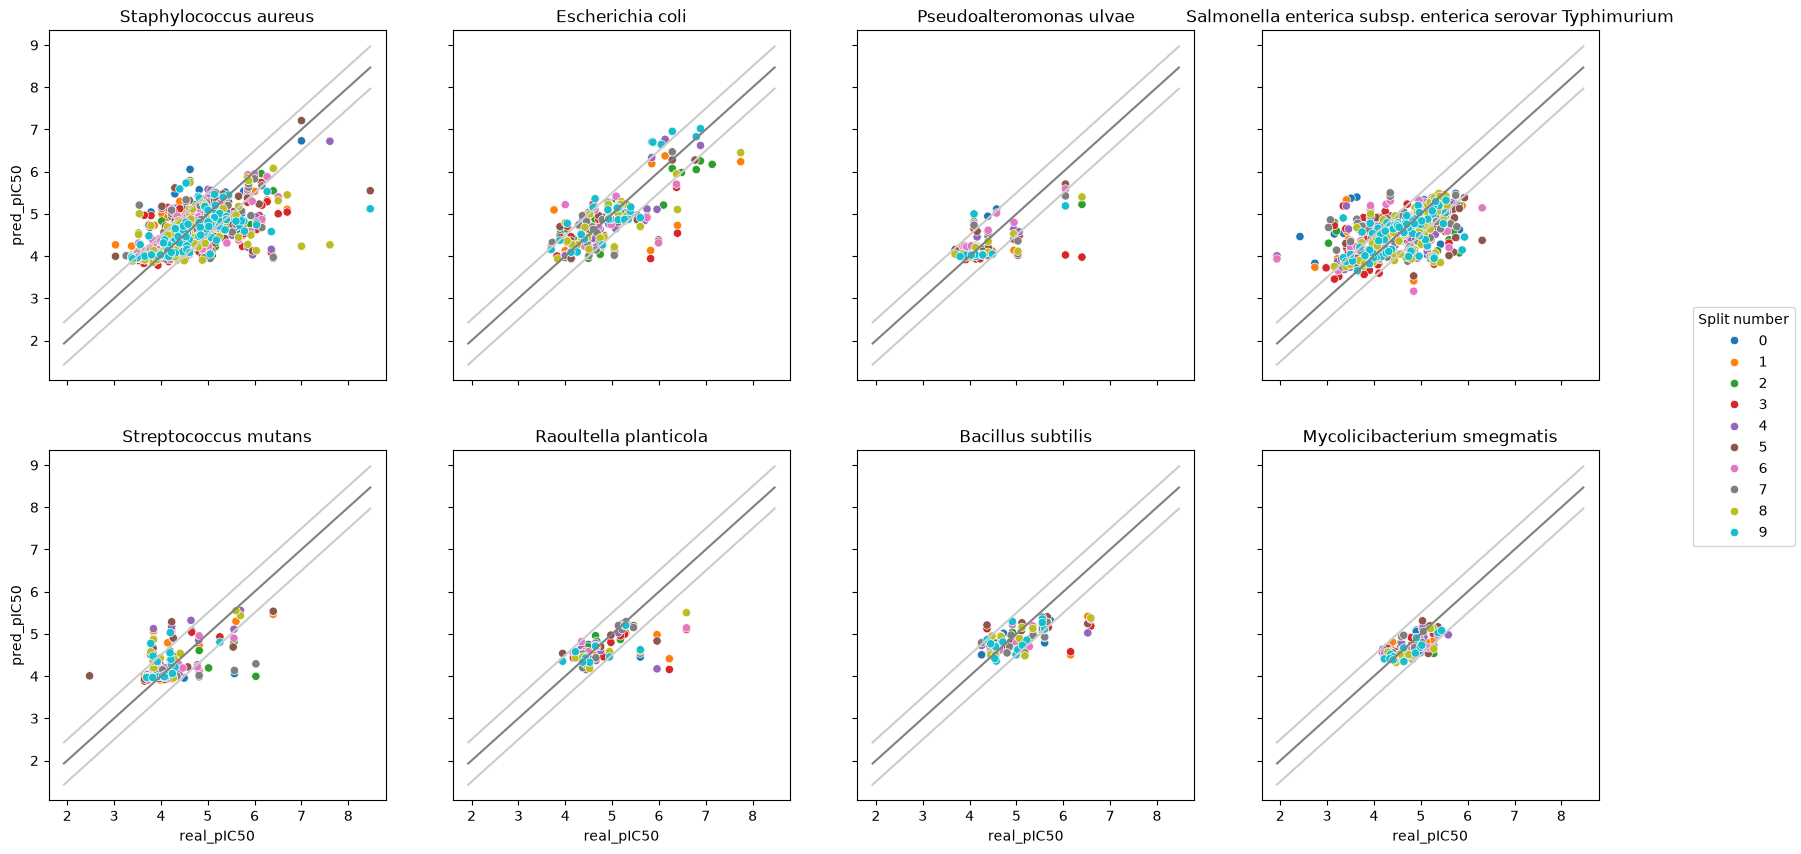

In [5]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [6]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.361,0.111,0.403,0.049,0.572,0.089
Escherichia coli,0.447,0.266,0.366,0.057,0.503,0.112
Pseudoalteromonas ulvae,0.259,0.437,0.368,0.111,0.492,0.200
Salmonella enterica subsp. enterica serovar Typhimurium,0.272,0.095,0.425,0.045,0.584,0.046
Streptococcus mutans,0.126,0.392,0.389,0.089,0.529,0.138
Raoultella planticola,0.180,0.315,0.324,0.092,0.509,0.151
Bacillus subtilis,0.286,0.150,0.339,0.066,0.461,0.116
Mycolicibacterium smegmatis,0.414,0.222,0.201,0.032,0.248,0.039


In [7]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.3536528196779175
MAE 0.4030082809293289
MSE 0.33350129223027075
RMSE 0.5774957075427234
..............
Escherichia coli
r2_score 0.5033192207542483
MAE 0.36556185082952186
MSE 0.2634743991106851
RMSE 0.5132975736458191
..............
Pseudoalteromonas ulvae
r2_score 0.30797229463056086
MAE 0.3675223577109267
MSE 0.2768230803094786
RMSE 0.5261397916043593
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.28728879852223854
MAE 0.42551256723177167
MSE 0.34266631862402835
RMSE 0.5853770738797586
..............
Streptococcus mutans
r2_score 0.2409828637411937
MAE 0.38381564423234105
MSE 0.2862156329534554
RMSE 0.5349912456792685
..............
Raoultella planticola
r2_score 0.22151448417103659
MAE 0.3237168175071728
MSE 0.2797625489462603
RMSE 0.5289258444680693
..............
Bacillus subtilis
r2_score 0.27207620050551107
MAE 0.3400455969474999
MSE 0.22364432735128364
RMSE 0.47291048555861354
..............
Mycolicibacterium 